# 02 — Smoke Tests, Ignore-Policy Ablation & Protocol

Smoke tests of the three training engines; `blur` vs `drop` for ignore regions (YOLO11n, k=10, 27 min each); the fixed protocol P0.

In [1]:
import os, sys
from pathlib import Path

if Path.cwd().name == "notebooks":          # always run from the repository root
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path("src").resolve()))  # use the local `vdet` package even without `pip install -e .`

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from vdet.paths import P
from vdet.notebook import *   # setup_notebook, results_table, show_image, *_experiment, evaluate_preds, ...

setup_notebook(seed=42)

# Training cells are resumable: a run whose checkpoint already exists in checkpoints/ is not
# trained again (its training log and metrics are loaded). Delete the checkpoint to retrain.

Project root : /home/marko/ucu-ai-hw-2
Data         : /home/marko/ucu-ai-hw-2/data (exists=True)
Cache        : /home/marko/ucu-ai-hw-2/cache (exists=True)
Checkpoints  : /home/marko/ucu-ai-hw-2/checkpoints
Device       : NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Smoke tests

In [2]:
YOLO_SMOKE = dict(
    run_id="yolo-smoke-local", family="yolo", exp="smoke",
    hypothesis="Verify end-to-end training, adapter, prediction, evaluator, and submission pipeline by overfitting 20 train frames locally.",
    model="yolo11n.pt", cache="k5_blur_L1920", max_train_images=20, val_on_train=True,
    imgsz=640, batch=2, epochs=60, time_budget_h=0.12, close_mosaic=10, mosaic=0.0, workers=2, auto_eval_val=False,
)
train_ultralytics_run(YOLO_SMOKE, benchmark=False)

# end-to-end check on the first 50 val frames
from vdet.eval.coco_eval import evaluate
smoke_preds = P.runs / "yolo-smoke-local" / "preds_val50.parquet"
if not smoke_preds.exists():
    predict_split(P.ckpt / "yolo-smoke-local_best.pt", "val", smoke_preds, imgsz=640, batch=2,
                  max_frames=50, source_tag="yolo-smoke-local")
if smoke_preds.exists():
    df = pd.read_parquet(smoke_preds)
    m = evaluate(df, split="val", subset=df["image_key"].unique().tolist())
    print(f"smoke AP on 50 val frames = {m['AP']:.4f} (sanity check only)")

[yolo-smoke-local] training completed earlier (yolo-smoke-local_best.pt); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.00203,0.00025,6.62963,2.31964,3.05691,0.05525,0.15430,0.0
1,2,0.00240,0.00052,6.54536,2.30870,2.98961,0.05572,0.15621,0.0
2,3,0.00269,0.00079,6.47332,2.32438,2.86814,0.05572,0.15621,0.0
3,4,0.00295,0.00081,6.40931,2.29942,2.84701,0.05586,0.14940,0.0
4,5,0.00320,0.00081,7.04465,2.47673,3.28629,0.05586,0.14940,0.0
...,...,...,...,...,...,...,...,...,...
454,455,0.11907,0.00002,2.31001,0.92549,0.55826,0.63403,0.94195,0.0
455,456,0.11933,0.00002,2.28559,0.91347,0.54681,0.63403,0.94195,0.0
456,457,0.11960,0.00001,2.30665,0.96041,0.53954,0.63403,0.94195,0.0
457,458,0.11987,0.00001,2.26310,0.89940,0.54181,0.63646,0.94158,0.0


[yolo-smoke-local] logged without validation metrics (smoke test).


smoke AP on 50 val frames = 0.0172 (sanity check only)


In [3]:
TV_SMOKE_COMMON = dict(
    exp="smoke", parent_run="", seed=42, cache="k5_drop_L1920", k=5,
    imgsz=640, min_size=384, max_size=640, num_classes=9, trainable_backbone_layers=3,
    max_train_images=20, val_on_train=True, batch=2, workers=2, epochs=6, time_budget_h=0.15,
    optimizer="sgd", lr=0.005, momentum=0.9, weight_decay=0.0001, warmup_epochs=1.0, grad_clip_norm=10.0,
    augmentation=dict(hflip=0.0, scale_min=1.0, scale_max=1.0, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0),
    inference=dict(conf_thresh=0.001, nms_iou=0.6, max_det=500, slim_conf_thresh=0.05),
)
FRCNN_SMOKE = dict(TV_SMOKE_COMMON, run_id="frcnn-smoke-local", family="faster_rcnn", roi_box_loss="giou",
                   hypothesis="Verify Faster R-CNN training loop, AMP, warmup+cosine LR, and checkpoint resume on 20 cached frames.")
RETINA_SMOKE = dict(TV_SMOKE_COMMON, run_id="retina-smoke-local", family="retinanet", use_kmeans_anchors=True,
                    focal_alpha=0.25, focal_gamma=1.5, fg_iou_thresh=0.4, bg_iou_thresh=0.3, box_loss_type="giou",
                    hypothesis="Verify RetinaNet training loop, k-means anchors, focal loss + matcher patch on 20 cached frames.")

for cfg in (FRCNN_SMOKE, RETINA_SMOKE):
    train_torchvision_run(cfg, benchmark=False)

[frcnn-smoke-local] training completed earlier (frcnn-smoke-local_best.pth); loading its training log.


,epoch,gpu_time_h,lr,train_loss
0,1,0.0013,0.00500,2.80501
1,2,0.0023,0.00037,0.91785
2,1,0.0012,0.00500,2.80332
3,2,0.0022,0.00463,0.89172
4,3,0.0032,0.00350,0.52766
5,4,0.0042,0.00203,0.38684
6,5,0.0051,0.00080,0.33354
7,6,0.0060,0.00025,0.32038


[frcnn-smoke-local] logged without validation metrics (smoke test).
[retina-smoke-local] training completed earlier (retina-smoke-local_best.pth); loading its training log.


,epoch,gpu_time_h,lr,train_loss
0,1,0.0010,0.00500,1.86188
1,2,0.0017,0.00037,1.73594
2,1,0.0009,0.00500,1.86188
3,2,0.0015,0.00463,1.72101
4,3,0.0021,0.00350,1.56265
5,4,0.0027,0.00203,1.40940
6,5,0.0033,0.00080,1.30661
7,6,0.0038,0.00025,1.26434


[retina-smoke-local] logged without validation metrics (smoke test).


## 2. Ignore-policy ablation: `blur` vs `drop`

In [4]:
U12_COMMON = dict(family="yolo", model="yolo11n.pt", train_subset_stride=2, imgsz=1280, batch=4,
                  epochs=40, time_budget_h=0.45, close_mosaic=3, workers=4, auto_eval_val=True)
U12_BLUR = dict(U12_COMMON, run_id="yolo-u12_blur", exp="u12_blur", cache="k5_blur_L1920",
                hypothesis="Soft-edged GT-protected Gaussian blur inside ignore regions prevents false-negative supervision without creating hard grey borders.")
U12_DROP = dict(U12_COMMON, run_id="yolo-u12_drop", exp="u12_drop", cache="k5_drop_L1920", parent_run="yolo-u12_blur",
                hypothesis="Compare unmodified ignore pixels ('drop') against GT-protected Gaussian blur ('blur') under identical seed and compute budget.")

for cfg in (U12_BLUR, U12_DROP):
    train_ultralytics_run(cfg, benchmark=False)

[yolo-u12_blur] training completed earlier (yolo-u12_blur_best.pt); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.03266,0.00028,4.36820,1.75962,1.44584,0.16241,0.32601,0.0
1,2,0.06034,0.00052,3.98207,1.67718,1.17879,0.15691,0.32314,0.0
2,3,0.08788,0.00072,3.86441,1.64587,1.10620,0.17548,0.37104,0.0
3,4,0.11590,0.00068,3.80167,1.62776,1.06795,0.16470,0.34306,0.0
4,5,0.14374,0.00063,3.69484,1.58607,1.02070,0.17677,0.36166,0.0
5,6,0.17178,0.00058,3.64284,1.57189,0.99180,0.17482,0.35515,0.0
6,7,0.19942,0.00052,3.59999,1.55870,0.96192,0.18151,0.37012,0.0
7,8,0.22585,0.00047,3.53825,1.53251,0.93678,0.18663,0.37133,0.0
8,9,0.25366,0.00042,3.51161,1.52356,0.92116,0.20207,0.39924,0.0
9,10,0.28079,0.00037,3.46237,1.50575,0.89827,0.18512,0.36816,0.0


[yolo-u12_blur] AP=0.1873 | AP50=0.3699 | APs=0.0952 | AR500=0.3143 | epochs=17 | gpu_h=0.4518 | fps=
[yolo-u12_drop] training completed earlier (yolo-u12_drop_best.pt); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.02851,0.00028,4.39787,1.75551,1.47978,0.17004,0.33985,0.0
1,2,0.05595,0.00052,4.00311,1.67500,1.20164,0.17637,0.34572,0.0
2,3,0.08320,0.00074,3.89008,1.64162,1.13600,0.17268,0.35381,0.0
3,4,0.10996,0.00069,3.81332,1.62245,1.08630,0.17336,0.35063,0.0
4,5,0.13688,0.00064,3.72879,1.58762,1.05018,0.19351,0.38366,0.0
5,6,0.16322,0.00059,3.66185,1.56984,1.01310,0.16933,0.34567,0.0
6,7,0.19013,0.00054,3.62320,1.55923,0.98482,0.18378,0.36762,0.0
7,8,0.21700,0.00049,3.55255,1.52992,0.95402,0.19698,0.38356,0.0
8,9,0.24381,0.00044,3.53722,1.52581,0.94331,0.20482,0.40122,0.0
9,10,0.27075,0.00040,3.49454,1.51053,0.92410,0.18793,0.36681,0.0


[yolo-u12_drop] AP=0.1912 | AP50=0.3712 | APs=0.0890 | AR500=0.3283 | epochs=17 | gpu_h=0.4521 | fps=


,AP,AP50,APs,border_ring_pct
blur,0.187267,0.369850,0.095200,3.064
drop,0.191195,0.371239,0.089002,2.220


Winner (fixed in protocol P0): drop


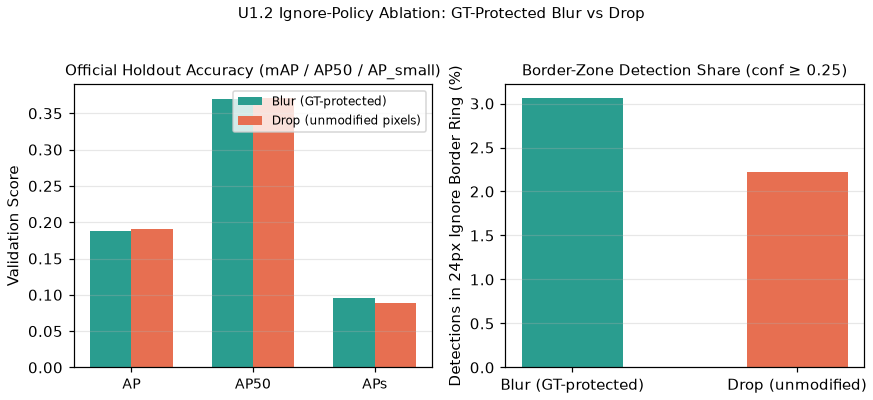

In [5]:
from vdet.eval.ignore_ablation import plot_ignore_ablation
from vdet.utils import load_json, save_json

summary_path = P.experiments / "u12_ignore_ablation_summary.json"
if not summary_path.exists() or not (P.images / "ignore_ablation.png").exists():
    save_json(plot_ignore_ablation(P.exp_runs_dir / "yolo-u12_blur", P.exp_runs_dir / "yolo-u12_drop",
                                   P.images / "ignore_ablation.png"), summary_path)
abl = load_json(summary_path)
display(pd.DataFrame({k: abl[k] for k in ("blur", "drop")}).T)
print("Winner (fixed in protocol P0):", abl["winner"])
show_image("ignore_ablation.png", 800)

**Decision:** `drop` (higher AP, fewer detections near ignore borders) is fixed in protocol P0.

## 3. Protocol P0 (shared by all training runs)

In [6]:
import yaml
from vdet.config import PROTOCOL
print(yaml.safe_dump(PROTOCOL, sort_keys=False))

protocol_id: P0
seed: 42
data:
  train_split: train
  holdout_split: val
  frame_step_k: 5
  val_proxy_k: 5
  ignore_policy: drop
  cache_long_side: 1920
  cache_name: k5_drop_L1920
  jpeg_quality: 95
input:
  imgsz: 1280
  min_size: 720
  max_size: 1280
training:
  pretrained: coco
  time_budget_h: 1.5
  warmup_epochs: 1.0
  close_mosaic_frac: 0.1
augmentation:
  hflip: 0.5
  vflip: 0.0
  degrees: 0.0
  scale_min: 0.5
  scale_max: 1.0
  hsv_h: 0.015
  hsv_s: 0.4
  hsv_v: 0.3
inference:
  conf_thresh: 0.001
  slim_conf_thresh: 0.05
  nms_iou: 0.6
  max_det: 500
  imgsz: 1280
evaluation:
  evaluator: faster-coco-eval
  iou_thresholds:
  - 0.5
  - 0.55
  - 0.6
  - 0.65
  - 0.7
  - 0.75
  - 0.8
  - 0.85
  - 0.9
  - 0.95
  max_dets:
  - 1
  - 10
  - 500
  size_buckets:
    small:
    - 0
    - 1024
    medium:
    - 1024
    - 9216
    large:
    - 9216
    - 10000000000
fps_benchmark:
  device: cuda
  batch_size: 1
  fp16: true
  imgsz: 1280
  warmup_frames: 20
  timed_frames: 200
  exclu